# Google Trends로 살펴본 한국 마라탕 유행의 확산과 재유행 요인: 2019·2022·2024년 정점 비교

- 데이터: Google Trends, 검색어 "마라탕", 지역 대한민국, 월별
- 값의 의미: 검색 **횟수가 아니라** 전체 다운로드 기간(2015-12~2026-09) 중 최고점을 100으로 둔 **상대 관심도 지수(0~100)**
- 분석 범위: 2016-01 ~ 2026-09 (129개월). 2015-12는 한 달뿐이라 연도 단위를 맞추려고 제외

**분석 질문**
1. 언제부터 마라탕 관심도가 오르기 시작했나?
2. 최상위 관심도는 언제 나타났고, 왜 그렇게 됐으며, 얼마나 유지됐나? (2019·2022·2024년 세 정점 비교)
3. 계절별로 관심도 차이가 있나? 마라탕에 대한 관심은 꾸준히 유지되고 있나?

## 0. 환경 설정

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.seasonal import STL

plt.rcParams.update({
    "font.family": "Malgun Gothic",   # 한글 폰트 (Windows)
    "axes.unicode_minus": False,
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#898781",
    "ytick.color": "#898781",
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.titlelocation": "left",
})

# 차트 색상 (역할별로 고정)
BLUE, ORANGE, RED, GRAY = "#2a78d6", "#eb6834", "#e34948", "#898781"
INK, INK2 = "#0b0b0b", "#52514e"

DATA_PATH = "data/maratang_kr_raw.csv"
IMG_DIR = "images"

## 1. 데이터 불러오기 및 기본 정보 확인

In [2]:
raw = pd.read_csv(DATA_PATH, parse_dates=["Time"])
print(raw.shape)
print(raw.dtypes)
raw.head()

(130, 2)
Time    datetime64[us]
마라탕              int64
dtype: object


,Time,마라탕
0,2015-12-01,3
1,2016-01-01,2
2,2016-02-01,0
3,2016-03-01,2
4,2016-04-01,2


In [3]:
print("기간:", raw["Time"].min().date(), "~", raw["Time"].max().date())
print("결측치:\n", raw.isna().sum())
print("중복 날짜:", raw["Time"].duplicated().sum())

# 월 단위로 빠진 달이 없는지 확인
full_range = pd.date_range(raw["Time"].min(), raw["Time"].max(), freq="MS")
print("누락된 달:", sorted(set(full_range) - set(raw["Time"])))

기간: 2015-12-01 ~ 2026-09-01
결측치:
 Time    0
마라탕     0
dtype: int64
중복 날짜: 0
누락된 달: []


## 2. 정제

| 항목 | 확인 결과 | 처리 기준 |
|---|---|---|
| 분석 기간 | 원본은 2015-12 ~ 2026-09 (130개월) | 2016-01 ~ 2026-09 사용 (2015-12 한 달만 제외해 연도 단위를 맞춤). 2026년은 9개월치라 연평균 비교 시 주의 |
| 결측치 | 없음, 누락된 달 없음 | 처리 불필요 |
| 0 값 | 2016년에 0이 2번 | Google Trends의 0은 "검색 없음"이 아니라 "1 미만"이라는 뜻. 원본 값은 그대로 두고, **변화율 계산에서만 0.5로 대체**해 0으로 나누는 문제(inf)를 막음 |
| 이상치 | 아래 STL 잔차로 판정 | 급등/급락 달은 입력 오류가 아니라 실제 관심 변화이므로 **제거하지 않고 표시만** 함 |

In [4]:
df = (raw.rename(columns={"Time": "date", "마라탕": "index"})
         .set_index("date")
         .loc["2016-01":"2026-09"]
         .copy())
print(len(df), "개월")
print("0 값인 달:", df.index[df["index"] == 0].strftime("%Y-%m").tolist())

df["index_safe"] = df["index"].replace(0, 0.5)   # 변화율 계산 전용
df.describe().T

129 개월
0 값인 달: ['2016-02', '2016-06']


,count,mean,std,min,25%,50%,75%,max
index,129.0,49.069767,30.034664,0.0,18.0,58.0,72.0,100.0
index_safe,129.0,49.077519,30.021961,0.5,18.0,58.0,72.0,100.0


## 3. 시계열 분석 지표

- **12개월 이동평균(MA12)**: 한 해 전체를 평균 내면 계절 요인과 월별 노이즈가 상쇄돼서 추세만 남음
- **전년 동월 대비 변화율(YoY)**: 같은 달끼리 비교하므로 계절성 영향 없이 성장 속도를 볼 수 있음
- **연도별 구간 통계**: 평균, 표준편차, 최소, 최대

In [5]:
df["ma12"] = df["index"].rolling(12).mean()
df["yoy"] = df["index_safe"].pct_change(12) * 100
df["year"] = df.index.year

yearly = df.groupby("year")["index"].agg(["mean", "std", "min", "max"]).round(1)
yearly["평균 대비 최고점(%)"] = (yearly["mean"] / df["index"].max() * 100).round(0)
yearly

,mean,std,min,max,평균 대비 최고점(%)
year,,,,,
2016,2.0,1.0,0,3,2.0
2017,5.8,2.8,3,12,6.0
2018,14.3,4.2,8,21,14.0
2019,56.2,21.2,26,98,56.0
2020,40.9,6.0,32,53,41.0
2021,52.2,6.3,45,61,52.0
2022,79.0,13.7,59,100,79.0
2023,75.3,9.0,63,88,75.0
2024,72.8,13.2,58,98,73.0


## Q1. 관심도는 언제부터 오르기 시작했나?

"붐 시작"을 눈대중이 아니라 숫자 기준으로 정의:

- **① 관심 상승 관찰 시작**: YoY가 +100% 이상(전년의 2배 이상)인 상태가 **6개월 연속** 이어진 첫 달
- **② 대중화(폭발)**: 지수가 최고점의 절반(50)을 처음 넘은 달

주의: 2016~2017년 값은 0~12로 매우 작아서 Google Trends의 0 처리와 표본 노이즈 영향이 큼.
그래서 ①은 정확한 "유행 시작일"이 아니라 **대중 노출이 본격적으로 관찰되기 시작한 시기**로 해석함


In [6]:
over = (df["yoy"] >= 100).astype(int)
run = over.groupby((over != over.shift()).cumsum()).cumsum()
seed_end = run[run >= 6].index[0]                       # 6개월째 되는 달
seed_start = seed_end - pd.DateOffset(months=5)          # 연속 구간의 첫 달
boom = df.index[df["index"] >= 50][0]

print("① 관심 상승 관찰 시작:", seed_start.strftime("%Y-%m"))
print("② 대중화            :", boom.strftime("%Y-%m"))
df.loc["2017-06":"2019-09", ["index", "ma12", "yoy"]].round(1).T

① 관심 상승 관찰 시작: 2017-08
② 대중화            : 2019-05


date,2017-06-01,2017-07-01,2017-08-01,2017-09-01,2017-10-01,2017-11-01,2017-12-01,2018-01-01,2018-02-01,2018-03-01,...,2018-12-01,2019-01-01,2019-02-01,2019-03-01,2019-04-01,2019-05-01,2019-06-01,2019-07-01,2019-08-01,2019-09-01
index,6.0,4.0,6.0,8.0,7.0,12.0,9.0,10.0,8.0,11.0,...,21.0,26.0,26.0,34.0,47.0,64.0,74.0,98.0,74.0,66.0
ma12,3.2,3.3,3.7,4.1,4.5,5.3,5.8,6.4,6.8,7.4,...,14.3,15.7,17.2,19.1,22.0,26.4,31.5,38.6,43.2,47.2
yoy,1100.0,33.3,200.0,166.7,250.0,500.0,200.0,233.3,166.7,175.0,...,133.3,160.0,225.0,209.1,291.7,481.8,469.2,653.8,311.1,266.7


### 그래프 1. 전체 추세 (월별 지수 + 12개월 이동평균)

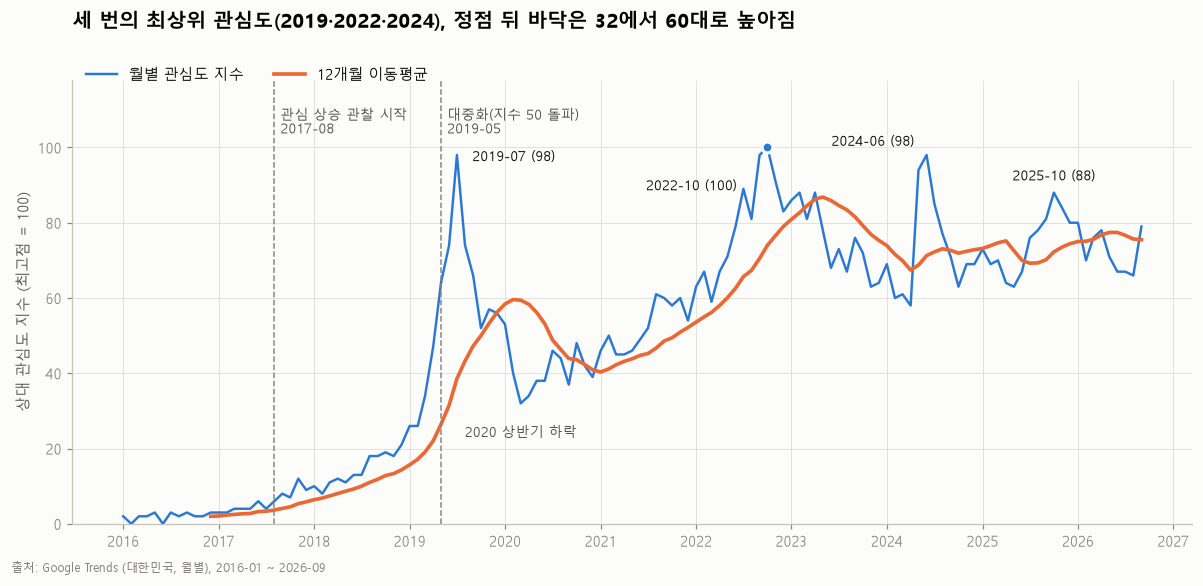

In [7]:
peak = df["index"].idxmax()

fig, ax = plt.subplots(figsize=(11, 5.2))
ax.plot(df.index, df["index"], color=BLUE, lw=1.6, label="월별 관심도 지수")
ax.plot(df.index, df["ma12"], color=ORANGE, lw=2.4, label="12개월 이동평균")

for x, label in [(seed_start, f"관심 상승 관찰 시작\n{seed_start:%Y-%m}"),
                 (boom, f"대중화(지수 50 돌파)\n{boom:%Y-%m}")]:
    ax.axvline(x, color=GRAY, lw=1, ls="--")
    ax.annotate(label, (x, 103), xytext=(4, 0), textcoords="offset points",
                ha="left", va="bottom", fontsize=9, color=INK2)

ax.scatter([peak], [df.loc[peak, "index"]], s=50, color=BLUE, zorder=3,
           edgecolor="#fcfcfb", linewidth=2)
ax.annotate(f"{peak:%Y-%m} (100)", (peak, 100), xytext=(-20, -28),
            textcoords="offset points", ha="right", fontsize=9, color=INK)
ax.annotate("2019-07 (98)", (pd.Timestamp("2019-07-01"), 98), xytext=(10, -4),
            textcoords="offset points", fontsize=9, color=INK)
ax.annotate("2024-06 (98)", (pd.Timestamp("2024-06-01"), 98), xytext=(-8, 6),
            textcoords="offset points", ha="right", fontsize=9, color=INK)
ax.annotate("2025-10 (88)", (pd.Timestamp("2025-10-01"), 88), xytext=(0, 8),
            textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.annotate("2020 상반기 하락", (pd.Timestamp("2020-03-01"), 32), xytext=(0, -22),
            textcoords="offset points", ha="center", fontsize=9, color=INK2)

ax.set_ylim(0, 118)
ax.set_ylabel("상대 관심도 지수 (최고점 = 100)")
ax.set_title("세 번의 최상위 관심도(2019·2022·2024), 정점 뒤 바닥은 32에서 60대로 높아짐", pad=34)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper left", frameon=False, bbox_to_anchor=(0, 1.06), ncol=2)
fig.text(0.01, -0.01, "출처: Google Trends (대한민국, 월별), 2016-01 ~ 2026-09", fontsize=8, color=GRAY)
fig.tight_layout()
fig.savefig(f"{IMG_DIR}/01_trend_moving_average.png", bbox_inches="tight")
plt.show()

### 그래프 2. 전년 동월 대비 변화율 (YoY)

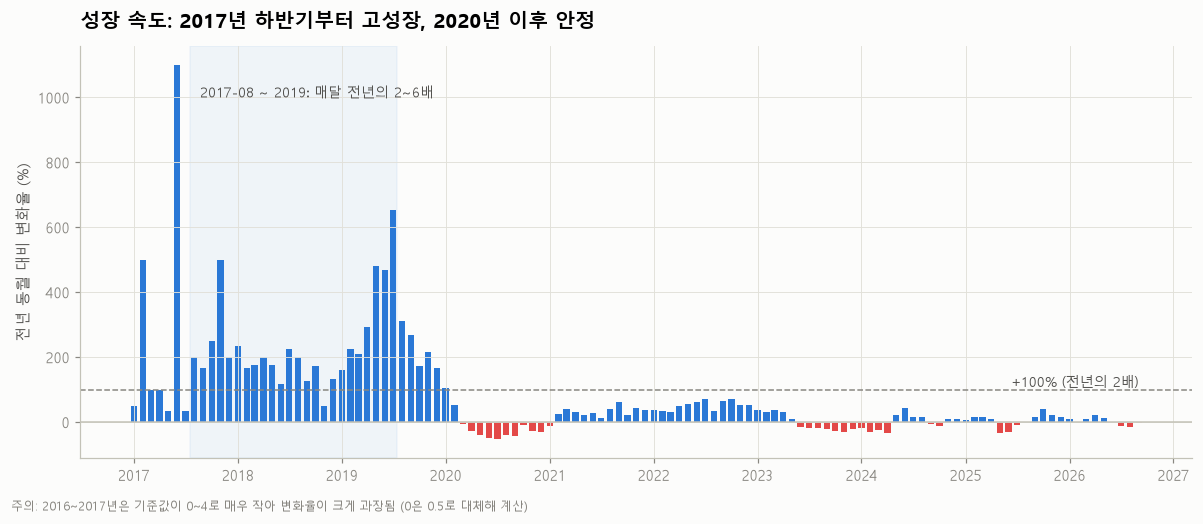

In [8]:
yoy = df["yoy"].dropna()
colors = np.where(yoy >= 0, BLUE, RED)

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.bar(yoy.index, yoy, width=22, color=colors)
ax.axhline(0, color="#c3c2b7", lw=1)
ax.axhline(100, color=GRAY, lw=1, ls="--")
ax.text(yoy.index[-1], 108, "+100% (전년의 2배)", ha="right", fontsize=9, color=INK2)
ax.axvspan(seed_start - pd.DateOffset(days=15), boom + pd.DateOffset(days=75), color=BLUE, alpha=0.06)
ax.text(seed_start + pd.DateOffset(days=20), 1000, "2017-08 ~ 2019: 매달 전년의 2~6배", fontsize=9, color=INK2)
ax.set_ylabel("전년 동월 대비 변화율 (%)")
ax.set_title("성장 속도: 2017년 하반기부터 고성장, 2020년 이후 안정", pad=12)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.text(0.01, -0.02, "주의: 2016~2017년은 기준값이 0~4로 매우 작아 변화율이 크게 과장됨 (0은 0.5로 대체해 계산)", fontsize=8, color=GRAY)
fig.tight_layout()
fig.savefig(f"{IMG_DIR}/02_yoy_change.png", bbox_inches="tight")
plt.show()

### Q1 원인 메모

데이터는 "언제"까지만 알려주고 "왜"는 알려주지 않음. 외부 자료로 확인한 근거는 REPORT.md에 정리함:

- 2017년 하반기: 대림동 등 중국인 상권 → KBS2 〈VJ특공대〉(2017-07), SBS 〈생활의 달인〉(2017-11) 지상파 노출. 2017년 중 가장 높은 달(11월, 12)이 〈생활의 달인〉 방영 시기와 겹침
- 2019년 봄~여름: 유튜브 먹방·ASMR 확산, 위메프 마라탕 재료 매출 전년 대비 +9,502% (2019년 1~5월)
- 2020년 상반기 하락: 아직 확인 전 (코로나19 시기와 겹침)

→ 2016~2017년 값은 0~12로 작아 표본 노이즈가 크므로, 방송 시기와 겹치는 것을 인과관계로 보지는 않음


## Q2. 최상위 관심도는 언제였고, 얼마나 지속됐나?

- 지속 기준: 지수 **80 이상**(최고점의 80%)이 **연속**된 개월 수

In [9]:
THRESH = 80
high = (df["index"] >= THRESH)
groups = (high != high.shift()).cumsum()
runs = (df[high].groupby(groups[high])
          .apply(lambda g: pd.Series({"시작": g.index[0].strftime("%Y-%m"),
                                      "끝": g.index[-1].strftime("%Y-%m"),
                                      "개월 수": len(g),
                                      "구간 최고값": g["index"].max()}))
          .reset_index(drop=True))
print("최고점:", peak.strftime("%Y-%m"), "=", df.loc[peak, "index"])
runs

최고점: 2022-10 = 100


,시작,끝,개월 수,구간 최고값
0,2019-07,2019-07,1,98
1,2022-07,2023-04,10,100
2,2024-05,2024-07,3,98
3,2025-09,2026-01,5,88


### 그래프 3. 고점 구간 비교 (지수 80 이상인 달 강조)

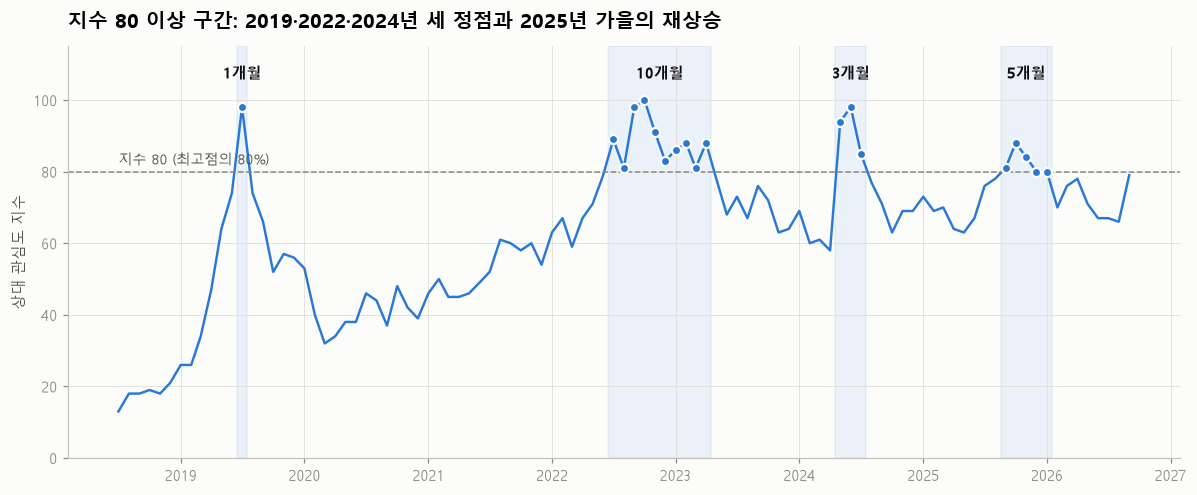

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.6))
sub = df.loc["2018-07":]
ax.plot(sub.index, sub["index"], color=BLUE, lw=1.6, zorder=2)
hi = sub[sub["index"] >= THRESH]
ax.scatter(hi.index, hi["index"], s=36, color=BLUE, zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
ax.axhline(THRESH, color=GRAY, lw=1, ls="--")
ax.text(sub.index[0], THRESH + 2, "지수 80 (최고점의 80%)", fontsize=9, color=INK2)

for _, r in runs.iterrows():
    s, e = pd.Timestamp(r["시작"]), pd.Timestamp(r["끝"])
    ax.axvspan(s - pd.DateOffset(days=15), e + pd.DateOffset(days=15), color=BLUE, alpha=0.08)
    ax.text(s + (e - s) / 2, 106, f"{r['개월 수']}개월", ha="center", fontsize=10, color=INK, weight="bold")

ax.set_ylim(0, 115)
ax.set_ylabel("상대 관심도 지수")
ax.set_title("지수 80 이상 구간: 2019·2022·2024년 세 정점과 2025년 가을의 재상승", pad=12)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
fig.savefig(f"{IMG_DIR}/03_peak_duration.png", bbox_inches="tight")
plt.show()

### Q2-2. 세 정점(2019-07 · 2022-10 · 2024-06) 지속 기간 비교

세 정점의 높이는 98 · 100 · 98로 사실상 같음 (Google Trends 지수는 표본 기반 정수라 2포인트 차이는 의미 있게 보기 어려움).
그래서 "어느 해가 가장 유행했나"보다 **"각 정점이 얼마나, 어떤 모양으로 유지됐나"**를 비교함.

지속 기간 기준을 하나만 쓰면 결과가 기준에 끌려가므로 세 가지를 같이 봄:

| 기준 | 정의 | 보려는 것 |
|---|---|---|
| 최상위 유지 | 지수 90 이상 연속 개월 | 정점 수준 그 자체가 얼마나 갔나 |
| 급등분 반감 | 직전 6개월 최저값과 정점의 중간값 이상 연속 개월 | 바닥 높이와 무관하게, 정점을 만든 "추가 관심"이 얼마나 갔나 |
| 고점권 유지 | 지수 80 이상 연속 개월 (Q2와 동일) | 높은 관심 구간 전체 |

추가로 **상승 속도**(직전 바닥 → 정점까지 개월), **3개월 뒤 유지율**, **정점 이후 12개월 내 바닥**을 비교함


In [11]:
PEAKS = {"2019-07": "2019 첫 대중화", "2022-10": "2022 정착·프로모션", "2024-06": "2024 마라탕후루"}

def run_around(mask, t):
    """t를 포함하는 mask==True 연속 구간 (시작, 끝, 개월 수)"""
    i = df.index.get_loc(t); a = b = i
    while a > 0 and mask.iloc[a - 1]: a -= 1
    while b < len(df) - 1 and mask.iloc[b + 1]: b += 1
    return df.index[a], df.index[b], b - a + 1

v = df["index"]
rows = []
for key, name in PEAKS.items():
    t = pd.Timestamp(key); i = v.index.get_loc(t)
    pre = v.iloc[i - 6:i]
    base, base_t = pre.min(), pre.idxmin()
    half = base + (v[t] - base) / 2
    after12 = v.iloc[i + 1:i + 13]
    rows.append({
        "정점": key, "구분": name, "정점 값": v[t],
        "직전 바닥": f"{base} ({base_t:%Y-%m})",
        "상승 기간(개월)": i - v.index.get_loc(base_t),
        "90 이상(개월)": run_around(v >= 90, t)[2],
        "급등분 반감 기준": round(half, 1),
        "반감 기준 이상(개월)": run_around(v >= half, t)[2],
        "80 이상(개월)": run_around(v >= THRESH, t)[2],
        "3개월 뒤 유지율(%)": round(v.iloc[i + 3] / v[t] * 100),
        "이후 12개월 바닥": f"{after12.min()} ({after12.idxmin():%Y-%m})",
        "정점 시 MA12": round(df["ma12"].iloc[i], 1),
    })
peak_cmp = pd.DataFrame(rows).set_index("정점")
peak_cmp.T

정점,2019-07,2022-10,2024-06
구분,2019 첫 대중화,2022 정착·프로모션,2024 마라탕후루
정점 값,98,100,98
직전 바닥,26 (2019-01),67 (2022-04),58 (2024-04)
상승 기간(개월),6,6,2
90 이상(개월),1,3,2
급등분 반감 기준,62.0,83.5,78.0
반감 기준 이상(개월),5,3,3
80 이상(개월),1,10,3
3개월 뒤 유지율(%),53,86,72
이후 12개월 바닥,32 (2020-03),67 (2023-08),63 (2024-10)


### 그래프 6. 세 정점을 같은 출발선에 겹쳐 보기 (정점 = 0개월)

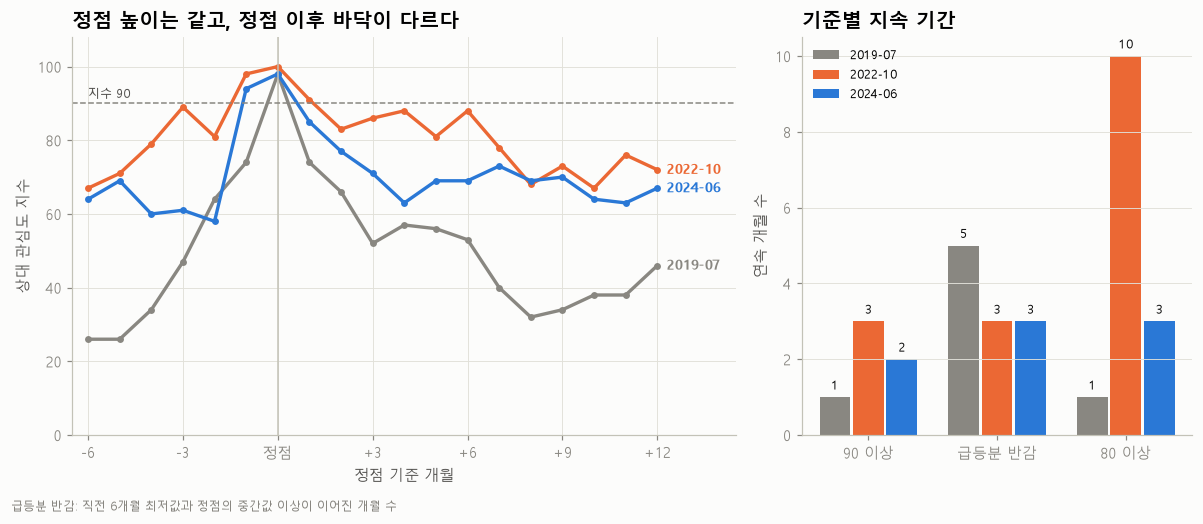

In [12]:
WIN = range(-6, 13)
pcolors = {"2019-07": GRAY, "2022-10": ORANGE, "2024-06": BLUE}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.7, 1]})
for key in PEAKS:
    i = v.index.get_loc(pd.Timestamp(key))
    ys = [v.iloc[i + k] for k in WIN]
    ax1.plot(list(WIN), ys, color=pcolors[key], lw=2.2, marker="o", ms=3.5)
    ax1.annotate(f"{key}", (WIN[-1], ys[-1]), xytext=(6, 0), textcoords="offset points",
                 va="center", fontsize=9, color=pcolors[key], weight="bold")
ax1.axvline(0, color="#c3c2b7", lw=1)
ax1.axhline(90, color=GRAY, lw=1, ls="--")
ax1.text(-6, 91.5, "지수 90", fontsize=8, color=INK2)
ax1.set_xticks(range(-6, 13, 3), [f"{k:+d}" if k else "정점" for k in range(-6, 13, 3)])
ax1.set_xlim(-6.5, 14.5); ax1.set_ylim(0, 108)
ax1.set_xlabel("정점 기준 개월")
ax1.set_ylabel("상대 관심도 지수")
ax1.set_title("정점 높이는 같고, 정점 이후 바닥이 다르다")

metrics = ["90 이상(개월)", "반감 기준 이상(개월)", "80 이상(개월)"]
labels = ["90 이상", "급등분 반감", "80 이상"]
w = 0.26
x = np.arange(len(metrics))
for j, key in enumerate(PEAKS):
    vals = peak_cmp.loc[key, metrics].astype(int).values
    bars = ax2.bar(x + (j - 1) * w, vals, w * 0.92, color=pcolors[key], label=key)
    for xb, val in zip(x + (j - 1) * w, vals):
        ax2.text(xb, val + 0.2, str(val), ha="center", fontsize=8.5, color=INK)
ax2.set_xticks(x, labels)
ax2.set_ylabel("연속 개월 수")
ax2.set_title("기준별 지속 기간")
ax2.legend(frameon=False, fontsize=8.5, loc="upper left")
ax2.grid(axis="x", visible=False)
fig.text(0.01, -0.02, "급등분 반감: 직전 6개월 최저값과 정점의 중간값 이상이 이어진 개월 수", fontsize=8, color=GRAY)
fig.tight_layout()
fig.savefig(f"{IMG_DIR}/06_peak_comparison.png", bbox_inches="tight")
plt.show()

## Q3-1. 계절별 차이가 있나?

월별 원본 값을 그대로 평균 내면 **상승 추세 때문에 계절 효과가 왜곡**됨. 그래서 STL로 추세를 먼저 구함.

다만 STL의 계절 성분은 "매년 비슷한 패턴이 반복된다"는 가정으로 매끄럽게 만든 값이라, 그것만 보면 계절성이 실제보다 일정해 보일 수 있음.
그래서 **연도별로** `원본 − STL 추세`(추세를 뺀 값)를 계절마다 평균 내서, 같은 계절이 해마다 높은지(=진짜 계절성인지) 확인함.

- 대상 기간: 2019-01 ~ 2025-12 (7개 연도). 2016~2018년은 값이 0~21로 작아서 계절 변동이 반올림 오차에 묻힘. 2026년은 가을이 9월 한 달뿐이라 연도별 비교에서 제외
- STL 자체는 2019-01 ~ 2026-09 전체로 추정
- 계절 구분: 봄(3~5월), 여름(6~8월), 가을(9~11월), 겨울(12~2월, 같은 해의 1·2·12월)


In [13]:
s = df.loc["2019-01":"2026-09", "index"].astype(float)
stl = STL(s, period=12, robust=True).fit()

season_map = {12: "겨울", 1: "겨울", 2: "겨울", 3: "봄", 4: "봄", 5: "봄",
              6: "여름", 7: "여름", 8: "여름", 9: "가을", 10: "가을", 11: "가을"}
order = ["봄", "여름", "가을", "겨울"]

comp = pd.DataFrame({"raw": s, "detr": s - stl.trend, "seasonal": stl.seasonal,
                     "year": s.index.year, "season": s.index.month.map(season_map)})
full = comp[comp["year"] <= 2025]

# 연도 × 계절 표
raw_ys = full.pivot_table(index="year", columns="season", values="raw", aggfunc="mean")[order].round(1)
detr_ys = full.pivot_table(index="year", columns="season", values="detr", aggfunc="mean")[order].round(1)
detr_ys["가장 높은 계절"] = detr_ys[order].idxmax(axis=1)
detr_ys["봄 > 가을"] = detr_ys["봄"] > detr_ys["가을"]

print("연도별 원본 계절 평균")
display(raw_ys)
print("연도별 추세 제거 값 (원본 − STL 추세, 지수 포인트)")
display(detr_ys)
print("가장 높은 계절이 된 횟수:", detr_ys["가장 높은 계절"].value_counts().reindex(order, fill_value=0).to_dict())
print("봄이 가을보다 높은 해:", detr_ys.index[detr_ys["봄 > 가을"]].tolist(),
      "(원본 기준:", raw_ys.index[raw_ys["봄"] > raw_ys["가을"]].tolist(), ")")

# 참고: STL 계절 성분 평균 (매년 반복 가정)
by_season = comp.groupby("season")["seasonal"].mean().loc[order].round(1)
print("참고: STL 계절 성분 평균", by_season.to_dict())

연도별 원본 계절 평균


season,봄,여름,가을,겨울
year,,,,
2019,48.3,82.0,58.3,36.0
2020,34.7,42.7,42.3,44.0
2021,45.3,54.0,59.3,50.0
2022,65.7,83.0,96.3,71.0
2023,82.3,69.3,70.3,79.3
2024,71.0,86.7,67.7,66.0
2025,65.7,73.7,84.3,74.0


연도별 추세 제거 값 (원본 − STL 추세, 지수 포인트)


season,봄,여름,가을,겨울,가장 높은 계절,봄 > 가을
year,,,,,,
2019,-13.2,24.0,3.9,-24.2,여름,False
2020,-13.0,-3.5,-3.7,-4.9,여름,False
2021,-4.3,0.8,1.6,-2.1,가을,False
2022,-5.4,5.9,15.4,0.4,가을,False
2023,3.8,-4.2,2.0,3.3,봄,True
2024,6.4,21.5,1.3,0.3,여름,True
2025,-5.8,-0.3,8.8,2.9,가을,False


가장 높은 계절이 된 횟수: {'봄': 1, '여름': 3, '가을': 3, '겨울': 0}
봄이 가을보다 높은 해: [2023, 2024] (원본 기준: [2023, 2024] )
참고: STL 계절 성분 평균 {'봄': -6.0, '여름': 1.0, '가을': 4.2, '겨울': -0.3}


### 그래프 4. 연도별 계절 차이: 같은 계절이 해마다 높은가?

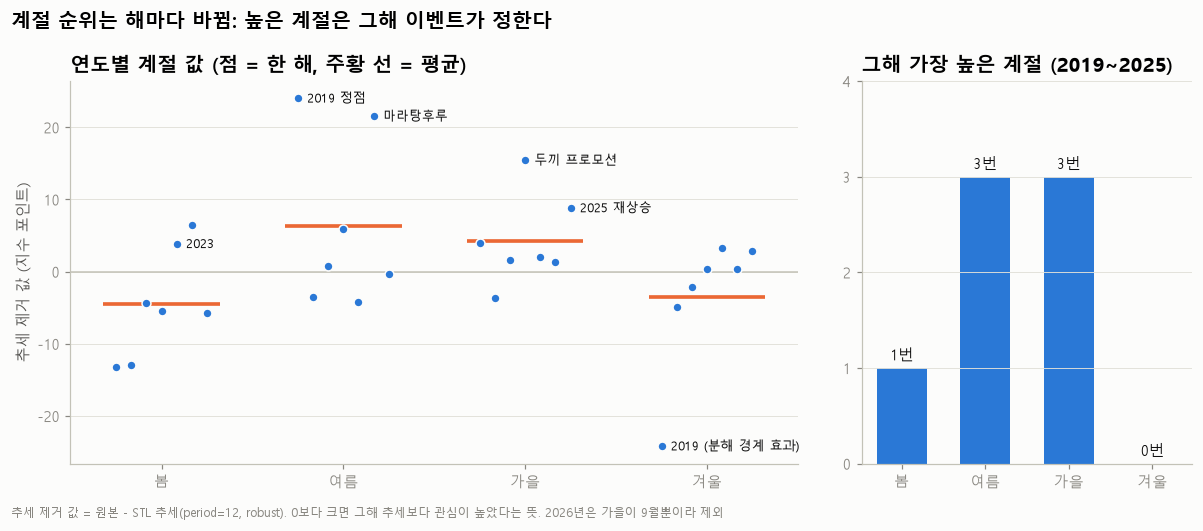

In [14]:
EVENTS = {(2019, "여름"): "2019 정점", (2022, "가을"): "두끼 프로모션",
          (2024, "여름"): "마라탕후루", (2025, "가을"): "2025 재상승",
          (2023, "봄"): "2023", (2019, "겨울"): "2019 (분해 경계 효과)"}
years = detr_ys.index.tolist()
offsets = np.linspace(-0.25, 0.25, len(years))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [2.2, 1]})
for j, season in enumerate(order):
    vals = detr_ys[season]
    ax1.scatter(j + offsets, vals, s=34, color=BLUE, zorder=3, edgecolor="#fcfcfb", linewidth=1)
    ax1.hlines(vals.mean(), j - 0.32, j + 0.32, color=ORANGE, lw=2.4, zorder=2)
    for (y, ss), label in EVENTS.items():
        if ss == season:
            k = years.index(y)
            ax1.annotate(label, (j + offsets[k], vals[y]), xytext=(6, 0), textcoords="offset points",
                         va="center", fontsize=8.5, color=INK)
ax1.axhline(0, color="#c3c2b7", lw=1)
ax1.set_xticks(range(4), order)
ax1.set_ylabel("추세 제거 값 (지수 포인트)")
ax1.set_title("연도별 계절 값 (점 = 한 해, 주황 선 = 평균)")
ax1.grid(axis="x", visible=False)

counts = detr_ys["가장 높은 계절"].value_counts().reindex(order, fill_value=0)
ax2.bar(order, counts.values, color=BLUE, width=0.6)
for i, c in enumerate(counts.values):
    ax2.text(i, c + 0.08, f"{c}번", ha="center", fontsize=10, color=INK)
ax2.set_ylim(0, max(counts) + 1)
ax2.set_yticks(range(0, max(counts) + 2))
ax2.set_title(f"그해 가장 높은 계절 ({years[0]}~{years[-1]})")
ax2.grid(axis="x", visible=False)

fig.suptitle("계절 순위는 해마다 바뀜: 높은 계절은 그해 이벤트가 정한다", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.text(0.01, -0.02, "추세 제거 값 = 원본 - STL 추세(period=12, robust). 0보다 크면 그해 추세보다 관심이 높았다는 뜻. 2026년은 가을이 9월뿐이라 제외",
         fontsize=8, color=GRAY)
fig.tight_layout()
fig.savefig(f"{IMG_DIR}/04_seasonality.png", bbox_inches="tight")
plt.show()

### (보너스 A) 시계열 분해: 추세 / 계절성 / 잔차

잔차가 큰 달(|z| > 2.5)은 **이상치 후보**로 표시함. 실제 이벤트일 가능성이 높아 제거하지는 않음.

이상치 후보: {'2019-01': -4.0, '2019-02': -2.82, '2019-07': 3.88, '2024-05': 3.21, '2024-06': 3.68}


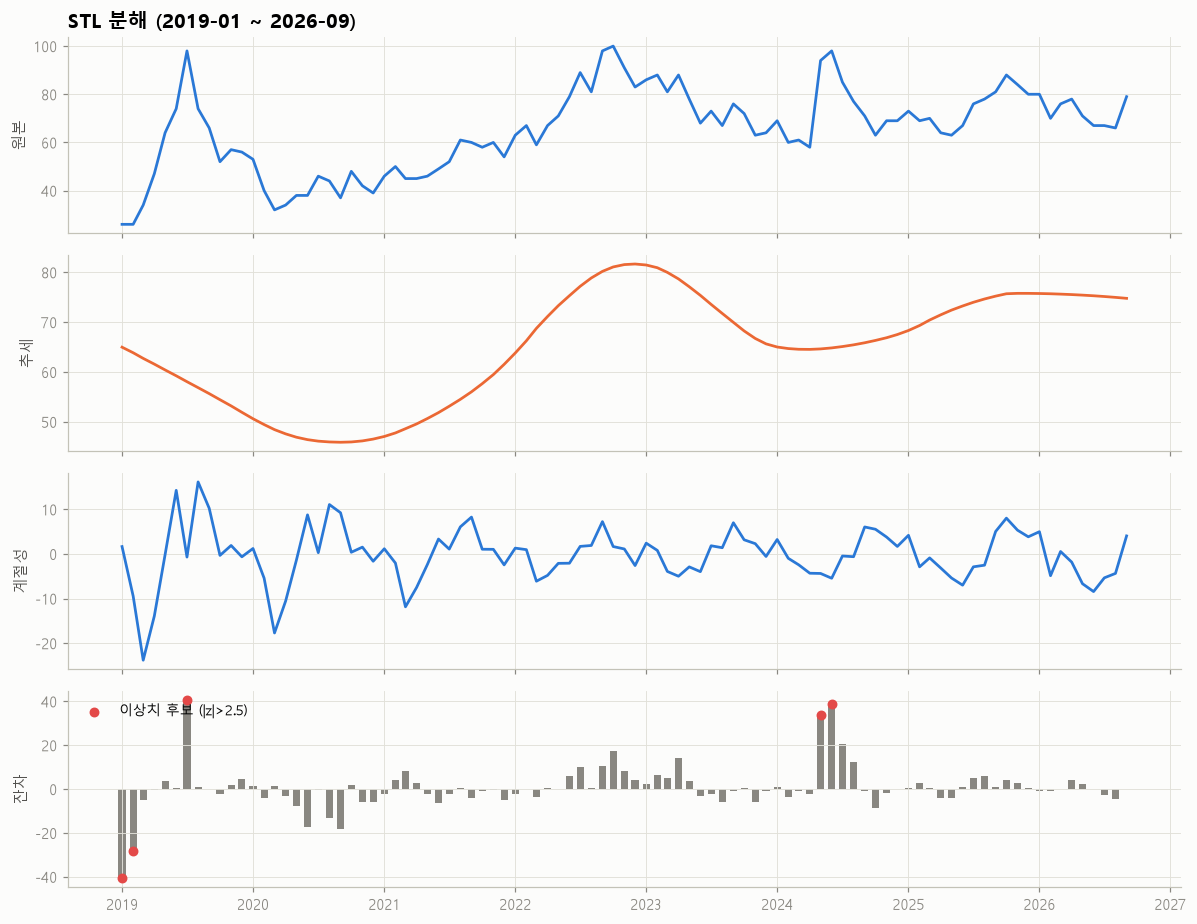

In [15]:
resid_z = (stl.resid - stl.resid.mean()) / stl.resid.std()
outliers = resid_z[resid_z.abs() > 2.5]
print("이상치 후보:", {d.strftime("%Y-%m"): round(z, 2) for d, z in outliers.items()})

fig, axes = plt.subplots(4, 1, figsize=(11, 8.5), sharex=True)
parts = [("원본", s, BLUE), ("추세", stl.trend, ORANGE),
         ("계절성", stl.seasonal, BLUE), ("잔차", stl.resid, GRAY)]
for ax, (name, ser, c) in zip(axes, parts):
    if name == "잔차":
        ax.bar(ser.index, ser, width=20, color=c)
        ax.scatter(outliers.index, stl.resid[outliers.index], color=RED, s=30, zorder=3, label="이상치 후보 (|z|>2.5)")
        ax.legend(frameon=False, loc="upper left", fontsize=9)
    else:
        ax.plot(ser.index, ser, color=c, lw=1.8)
    ax.set_ylabel(name)
axes[0].set_title("STL 분해 (2019-01 ~ 2026-09)")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
fig.savefig(f"{IMG_DIR}/05_stl_decomposition.png", bbox_inches="tight")
plt.show()

## Q3-2. 붐 이후에도 관심이 꾸준히 유지되고 있나?

- 비교 1: 2022년 정점 이후 연평균이 얼마나 줄었나
- 비교 2: 12개월 이동평균이 최고점 이후 계속 내려가는 중인가, 멈췄나 (2026은 9개월치)

In [16]:
summary = pd.DataFrame({
    "연평균": yearly["mean"],
    "전년 대비(%)": (yearly["mean"].pct_change() * 100).round(1),
    "최고점(100) 대비(%)": yearly["mean"].round(0),
})
display(summary.loc[2019:])

ma = df["ma12"]
print(f"MA12 최고: {ma.idxmax():%Y-%m} = {ma.max():.1f}")
after = ma.loc[ma.idxmax():]
print(f"MA12 최고점 이후 최저: {after.idxmin():%Y-%m} = {after.min():.1f}")
print(f"MA12 최종({ma.index[-1]:%Y-%m}): {ma.iloc[-1]:.1f} → 최고점의 {ma.iloc[-1] / ma.max() * 100:.0f}% 수준")
print(f"2022-01 이후 월별 지수 범위: {df.loc['2022':, 'index'].min()} ~ {df.loc['2022':, 'index'].max()}")

,연평균,전년 대비(%),최고점(100) 대비(%)
year,,,
2019,56.2,293.0,56.0
2020,40.9,-27.2,41.0
2021,52.2,27.6,52.0
2022,79.0,51.3,79.0
2023,75.3,-4.7,75.0
2024,72.8,-3.3,73.0
2025,74.4,2.2,74.0
2026,72.7,-2.3,73.0


MA12 최고: 2023-05 = 86.8
MA12 최고점 이후 최저: 2024-04 = 67.4
MA12 최종(2026-09): 75.5 → 최고점의 87% 수준
2022-01 이후 월별 지수 범위: 58 ~ 100


## 정리

각 질문의 관찰(수치)과 해석(가설), 외부 근거, 인사이트는 REPORT.md에 정리함.
